Esse notebook foi implementado para o trabalho final para a conclusão da disciplina de Supervised Machine Learning do PPGEE do Instituto de Pesquisa Científica da UNESP-Sorocaba.
Sob a autoria do aluno espescial Adauto Tadeu de Carvalho Junior e a orientação do professor Alexandre da Silva Simões.


In [1]:
#Importando as bibliotecas necessárias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
# Carregando o dataset para a escolha ca cultura
data = pd.read_csv('Crop_recommendation.csv')

In [3]:
#Visualizando as primeiras 5 linhas 
print(data.head())

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


In [4]:
#Verificando os valores ausentes
print(data.isnull().sum())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [12]:
#Separar variáveis de entrada e saída

X = data.drop('label', axis=1)
y = data['label']

# Dividir o dataset em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Escalar os dados
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



 ->KNN Relatório de Classificação:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.95      1.00      0.98        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       0.91      1.00      0.95        20
       maize       1.00      0.95      0.97        20
       mango       0.95      1.00      0.98        20
   mothbeans       0.94      0.85      0.89        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      0.90      0.95  

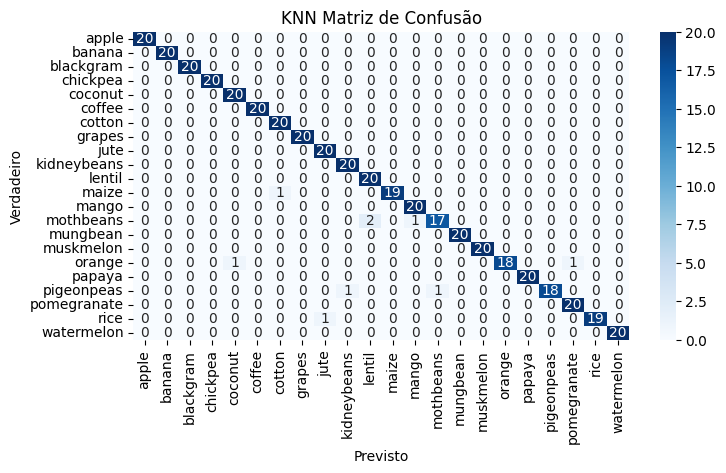

In [13]:
# Baseline: KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print("\n ->KNN Relatório de Classificação:")
print(classification_report(y_test, y_pred_knn))

print(" ->KNN Matriz de Confusão:")
plt.figure(figsize=(8, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues', xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel('Previsto')
plt.ylabel('Verdadeiro')
plt.title('KNN Matriz de Confusão')
plt.show()


 ->Random Forest Relatório de Classificação:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00  

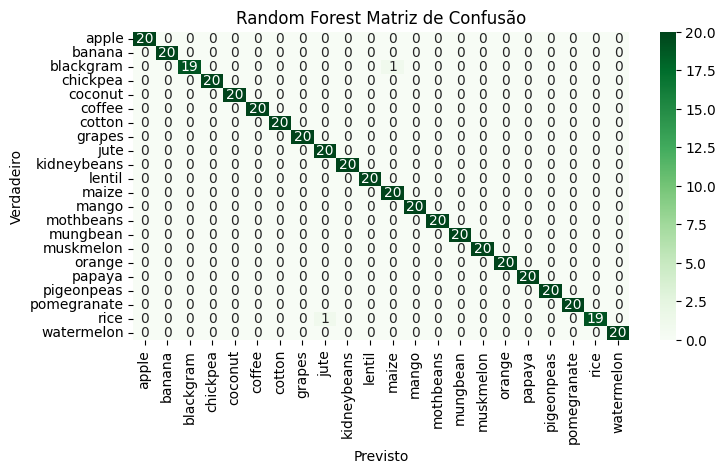

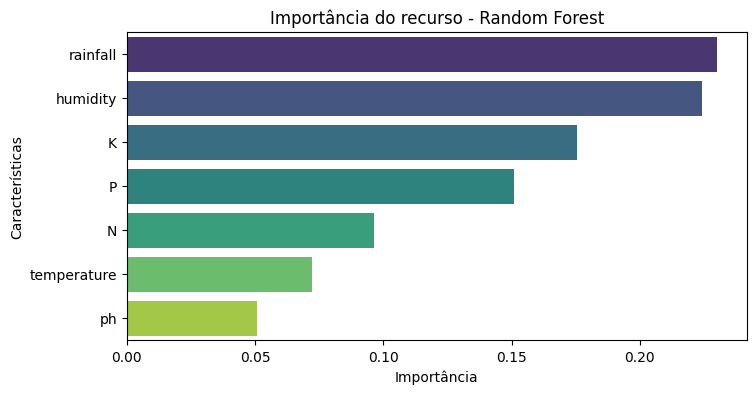

In [14]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("\n ->Random Forest Relatório de Classificação:")
print(classification_report(y_test, y_pred_rf))

print(" ->Random Forest Matriz de Confusão:")
plt.figure(figsize=(8, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.xlabel('Previsto')
plt.ylabel('Verdadeiro')
plt.title('Random Forest Matriz de Confusão')
plt.show()

# Importância dos Recursos
feature_importances = pd.Series(rf.feature_importances_, index=X.columns)
feature_importances = feature_importances.sort_values(ascending=False)

plt.figure(figsize=(8,4))
sns.barplot(x=feature_importances, y=feature_importances.index,hue=feature_importances.index, palette='viridis')
plt.title('Importância do recurso - Random Forest')
plt.xlabel('Importância')
plt.ylabel('Características')
plt.show()




 ->Tree Decision Relatório de Classificação:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00  

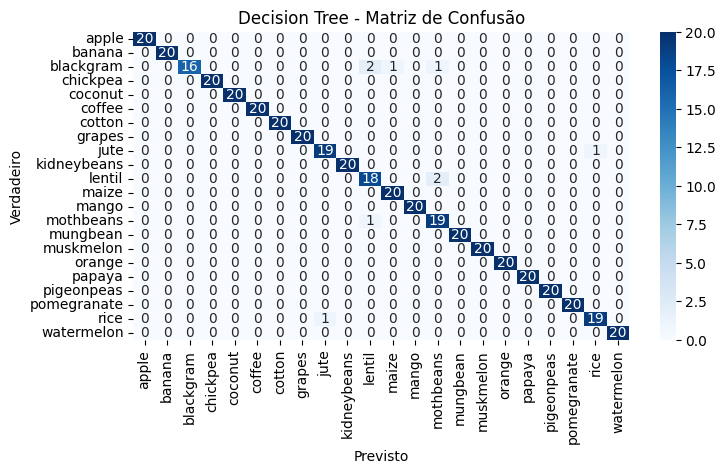


 ->SVM Relatório de Classificação:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.80      1.00      0.89        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      0.95      0.97        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00  

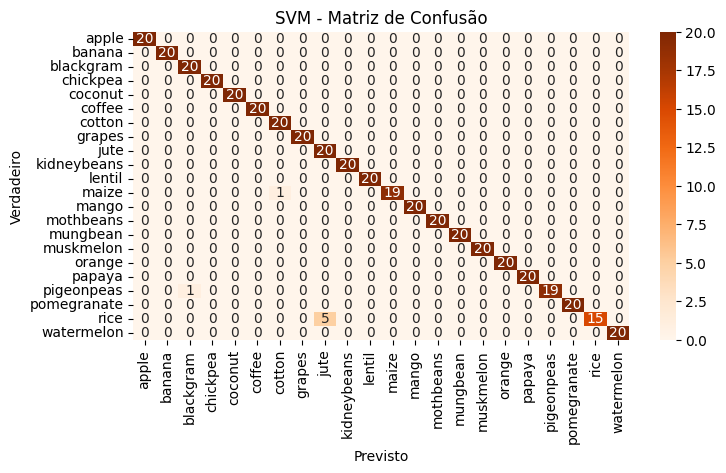

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
%matplotlib inline
#Treinando Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Treinando SVM
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

# Métricas
acc_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt, average='weighted')

#Exibindo a validação das métricas Árvore de Decisão
print("\n ->Tree Decision Relatório de Classificação:")
print(classification_report(y_test, y_pred_dt))
print(f"Decision Tree - Acurácia: {acc_dt:.2f}, F1-Score: {f1_dt:.2f}")

acc_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')


# Matriz de confusão Decision Tree
plt.figure(figsize=(8,4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues', xticklabels=dt.classes_, yticklabels=dt.classes_)
plt.title('Decision Tree - Matriz de Confusão')
plt.xlabel('Previsto')
plt.ylabel('Verdadeiro')
plt.show()

#Exibindo a validação das métricas SVM
print("\n ->SVM Relatório de Classificação:")
print(classification_report(y_test, y_pred_svm))
print(f"SVM - Acurácia: {acc_svm:.2f}, F1-Score: {f1_svm:.2f}")

# Matriz de confusão SVM
plt.figure(figsize=(8,4))
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Oranges', xticklabels=dt.classes_, yticklabels=dt.classes_)
plt.title('SVM - Matriz de Confusão')
plt.xlabel('Previsto')
plt.ylabel('Verdadeiro')
plt.show()

In [16]:
from sklearn.model_selection import cross_val_score

#Realizando a validação cruzada utilizando cv=5 
#Random Forest
scores_rf = cross_val_score(RandomForestClassifier(random_state=42), 
                            X, y, cv=5, scoring='accuracy')
print("Random Forest (Acurácia média com CV=5):", scores_rf.mean())

# Àrvore de Decisão
scores_dt = cross_val_score(DecisionTreeClassifier(random_state=42), 
                            X, y, cv=5, scoring='accuracy')
print("Decision Tree (Acurácia média com CV=5):", scores_dt.mean())


# KNN
scores_knn = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=5, scoring='accuracy')
print("KNN (Acurácia média com CV=5):", scores_knn.mean())

# SVM
scores_svm = cross_val_score(SVC(kernel='rbf', random_state=42), 
                             X, y, cv=5, scoring='accuracy')
print("SVM (Acurácia média com CV=5):", scores_svm.mean())


Random Forest (Acurácia média com CV=5): 0.9945454545454545
Decision Tree (Acurácia média com CV=5): 0.9868181818181819
KNN (Acurácia média com CV=5): 0.9795454545454545
SVM (Acurácia média com CV=5): 0.9781818181818182


In [20]:
#Testando se realmente há diferenças entre as acurácias com ANOVA
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Random Forest
scores_rf = cross_val_score(RandomForestClassifier(random_state=42), X, y, cv=5, scoring='accuracy')

# Decision Tree
scores_dt = cross_val_score(DecisionTreeClassifier(random_state=42), X, y, cv=5, scoring='accuracy')

# KNN
scores_knn = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=5, scoring='accuracy')

# SVM
scores_svm = cross_val_score(SVC(), X, y, cv=5, scoring='accuracy')


In [21]:
#Rodando o teste
from scipy.stats import f_oneway

# Realiza o teste ANOVA
anova_result = f_oneway(scores_rf, scores_dt, scores_knn, scores_svm)

print("Estatística F:", anova_result.statistic)
print("p-variavel:", anova_result.pvalue)


Estatística F: 22.448979591836856
p-variavel: 5.607041188574098e-06


In [23]:

#Para a 2a fase do projeto iremos instalar o tensorflow ecarregar as bibliotecas necessárias para criar a nossa DNN...
!pip install tensorflow
import tensorflow
from tensorflow.keras.datasets import PlantVillage 
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight


dataset = tf.keras.utils.image_dataset_from_directory(
    directory='./PlantVillage',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224, 224)
)

with np.load(path) as data:
    X_train = data['x_train']
    Y_train = data['y_train']
    X_test = data['x_test']
    Y_test = data['y_test']

print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)
print(Y_test.shape)

  Using cached tensorflow-2.19.0-cp312-cp312-win_amd64.whl.metadata (4.1 kB)
Using cached tensorflow-2.19.0-cp312-cp312-win_amd64.whl (376.0 MB)


ERROR: Could not install packages due to an OSError: [Errno 28] No space left on device


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


ImportError: cannot import name 'pywrap_tensorflow' from 'tensorflow.python' (C:\Python312\Lib\site-packages\tensorflow\python\__init__.py)